<h1>CRISP DM template (fi)</h1>

<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

Lets start by loading our dataset from the directory. The data set contains melspectograml images from voice samples, both in english and finnish language.

  - Down : Alas
  - Left : Vasen
  - Right : Oikea
  - Start : Päälle/Paalle
  - Stop : Pysähdy/Pysahdy
  - Up : Ylös/Ylos

In [64]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
from collections import Counter
import tensorflow as tf

img_samples = pathlib.Path("../data/image-samples")
print("Path found")

Path found


In [65]:
#SUPPORTS FORMATS: JPEG (.jpg, .jpeg), PNG (.png), BMP (.bmp) AND GIF (.gif)

# finnish data
train_dataset_fi = image_dataset_from_directory(
    img_samples / "train" / "finnish",
    image_size = (224, 224),
    batch_size = 32)

validation_dataset_fi = image_dataset_from_directory(
    img_samples / "validation" / "finnish",
    image_size = (224, 224),
    batch_size = 32)

test_dataset_fi = image_dataset_from_directory(
    img_samples / "test" / "finnish",
    image_size = (224, 224),
    batch_size = 32)

# english data
train_dataset_en = image_dataset_from_directory(
    img_samples / "train" / "english",
    image_size = (224, 224),
    batch_size = 32)

validation_dataset_en = image_dataset_from_directory(
    img_samples / "validation" / "english",
    image_size = (224, 224),
    batch_size = 32)

test_dataset_en = image_dataset_from_directory(
    img_samples / "test" / "english",
    image_size = (224, 224),
    batch_size = 32)

Found 140 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 140 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 18 files belonging to 6 classes.


We succesfully found all the saved files from bouth language folders. All collected images were resized to 224 × 224 pixels to ensure a consistent input size for the CNN model.

To have better knowledge of our data, we also inspect how many pictures each class contains. Since uneven amounts affect the models learning accuracy, and thus the model may favour some classes over the other ones.

In [66]:
class_names = ["up", "down", "left", "right", "start", "stop"]

for name, dataset in [
    ("Training Finnish", train_dataset_fi),
    ("Validation Finnish", validation_dataset_fi),
    ("Test Finnish", test_dataset_fi),
    ("Training English", train_dataset_en),
    ("Validation English", validation_dataset_en),
    ("Test English", test_dataset_en)
]:
    counts = Counter()

    for images, labels in dataset:
        counts.update(labels.numpy().tolist())

    print(name)

    for i, class_name in enumerate(class_names):
        print(class_name, ":", counts[i])

    print()

Training Finnish
up : 23
down : 24
left : 23
right : 23
start : 23
stop : 24

Validation Finnish
up : 3
down : 3
left : 3
right : 3
start : 3
stop : 3

Test Finnish
up : 3
down : 3
left : 3
right : 3
start : 3
stop : 3

Training English
up : 23
down : 23
left : 23
right : 23
start : 24
stop : 24

Validation English
up : 3
down : 3
left : 3
right : 3
start : 3
stop : 3

Test English
up : 3
down : 3
left : 3
right : 3
start : 3
stop : 3



Classes: ['down', 'left', 'right', 'start', 'stop', 'up']


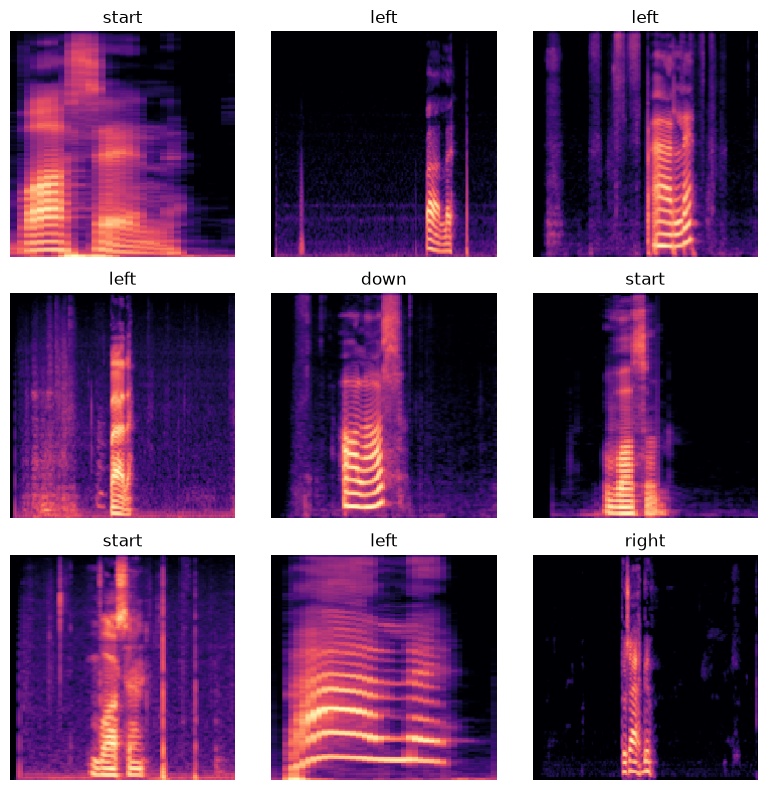

In [67]:
class_names = train_dataset_en.class_names
print("Classes:", class_names)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

This shows 9 images from the english training dataset with their class names. The images are displayed in a 3×3 grid. Each image has a label showing it's command. This helps to check that the images are loaded correctly and how each command sounds and looks like.

Let us also inspect the finnish training dataset the same way.

Classes: ['alas', 'oikea', 'paalle', 'pysahdy', 'vasen', 'ylos']


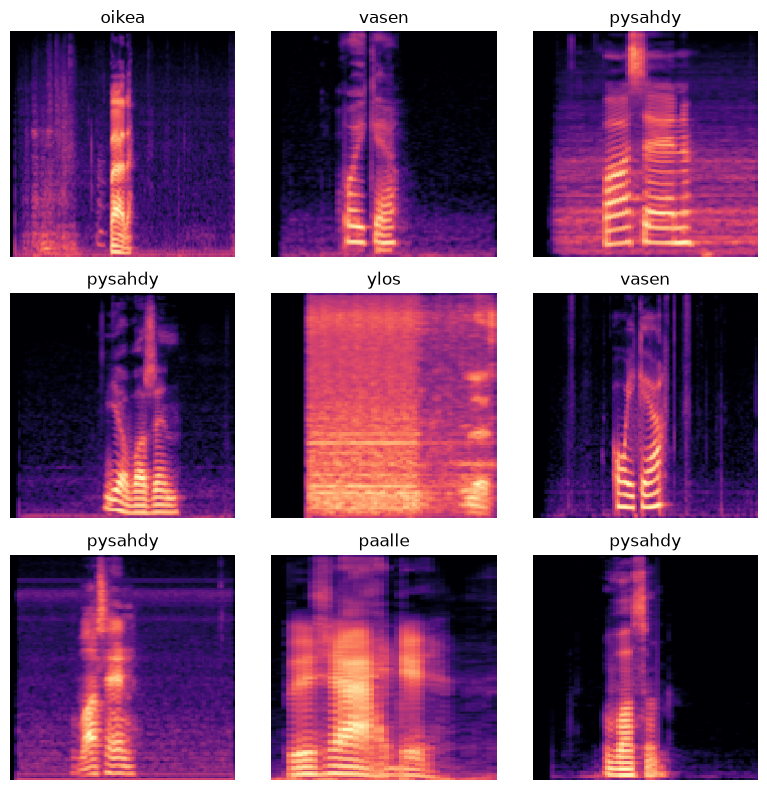

In [68]:
class_names = train_dataset_fi.class_names
print("Classes:", class_names)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.

We prepare or data my compiling english and finnish commands in the same class, so we can train the model in both languages. After that, to help our model to learn better, we changes image pixel values from 0–255 to 0–1.

Since both languages have different labels, we first compund labels to the same order.

In [69]:
import tensorflow as tf

class_names = ["up", "down", "left", "right", "start", "stop"]

# chech classes order
print(train_dataset_fi.class_names)
print(train_dataset_en.class_names)

['alas', 'oikea', 'paalle', 'pysahdy', 'vasen', 'ylos']
['down', 'left', 'right', 'start', 'stop', 'up']


As we see, the class labels do not match. And that is why we have to change the labels. We create function to change the labels and use it to each dataset.

In [70]:
finnish_mapping = tf.constant([1, 3, 4, 5, 2, 0])
english_mapping = tf.constant([1, 2, 3, 4, 5, 0])

def map_labels(dataset, mapping):
    return dataset.map(
        lambda images, labels: (images, tf.gather(mapping, labels))
    )

In [71]:
# finnish
train_fi = map_labels(train_dataset_fi, finnish_mapping)
val_fi = map_labels(validation_dataset_fi, finnish_mapping)
test_fi = map_labels(test_dataset_fi, finnish_mapping)

# english
train_en = map_labels(train_dataset_en, english_mapping)
val_en = map_labels(validation_dataset_en, english_mapping)
test_en = map_labels(test_dataset_en, english_mapping)

After the labels have been changed to match, we combine the languages. And when that is done, we also normalize and shuffle the data to help our model in learning.

In [72]:
# compine languages
train_dataset = train_fi.concatenate(train_en)

validation_dataset = val_fi.concatenate(val_en)

test_dataset = test_fi.concatenate(test_en)

In [73]:
# normalize pixel values from 0–255 to 0–1.
def normalize(images, labels):
    return images / 255.0, labels

train_ds = train_dataset.map(normalize)
val_ds = validation_dataset.map(normalize)
test_ds = test_dataset.map(normalize)

In [74]:
# shuffle the training data
train_ds = train_ds.shuffle(1000)

In [75]:
# display the result
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Labels:", labels.numpy())
    print("Pixel range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Labels: [4 1 1 5 0 5 2 5 0 2 2 1 3 4 3 1 0 0 3 3 4 5 5 0 3 4 4 3 5 4 2 5]
Pixel range: 0.0 0.99607843


In [78]:
# check that the labels match
print("Finnish mapping:")

for i, name in enumerate(train_dataset_fi.class_names):
    print(name, "->", int(finnish_mapping[i].numpy()))

print("\nEnglish mapping:")

for i, name in enumerate(train_dataset_en.class_names):
    print(name, "->", int(english_mapping[i].numpy()))

Finnish mapping:
alas -> 1
oikea -> 3
paalle -> 4
pysahdy -> 5
vasen -> 2
ylos -> 0

English mapping:
down -> 1
left -> 2
right -> 3
start -> 4
stop -> 5
up -> 0


Now the result tells, that the image data and labels are in the right format. The patch contains 32 images, where each picture is 224 x 224 pixels with 3 channels (RGB). 

The class designations are whole numbers between 0-5, pointing out each command.

<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.

`"layers.Dense(6, activation="softmax")" to be used in the last layer, so we get prediction for each class`

In [79]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)), # recives 224 x 224x rgb picture

    layers.Conv2D(32, (3, 3), activation="relu"), # conv learns features
    layers.MaxPooling2D((2, 2)), # max reduces pic size for show

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(), # combines learned features

    layers.Dense(128, activation="relu"), # dense learns similarities between classes
    layers.Dropout(0.3), # reduces over fitting

    layers.Dense(6, activation="softmax") # produces 6 class prediction
])

In [80]:
# define how the model learns
model.compile(
    optimizer="adam", # 
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
# train the model
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30


C:\Users\gerli\anaconda3\envs\Keras\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 499ms/step - accuracy: 0.1429 - loss: 1.7978 - val_accuracy: 0.2222 - val_loss: 1.7929
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 490ms/step - accuracy: 0.1607 - loss: 1.7943 - val_accuracy: 0.1667 - val_loss: 1.7917
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 483ms/step - accuracy: 0.1786 - loss: 1.7912 - val_accuracy: 0.1389 - val_loss: 1.7915
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 464ms/step - accuracy: 0.1607 - loss: 1.7936 - val_accuracy: 0.1667 - val_loss: 1.7916
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 445ms/step - accuracy: 0.1714 - loss: 1.7908 - val_accuracy: 0.1111 - val_loss: 1.7918
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 451ms/step - accuracy: 0.1321 - loss: 1.7922 - val_accuracy: 0.1667 - val_loss: 1.7918
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - accuracy: 0.1786 - loss: 1.7928 - val_accuracy: 0.1667 - val_loss: 1.7928
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - accuracy: 0.1571 - loss: 1.7887 - val_accuracy: 0.1667 - val_

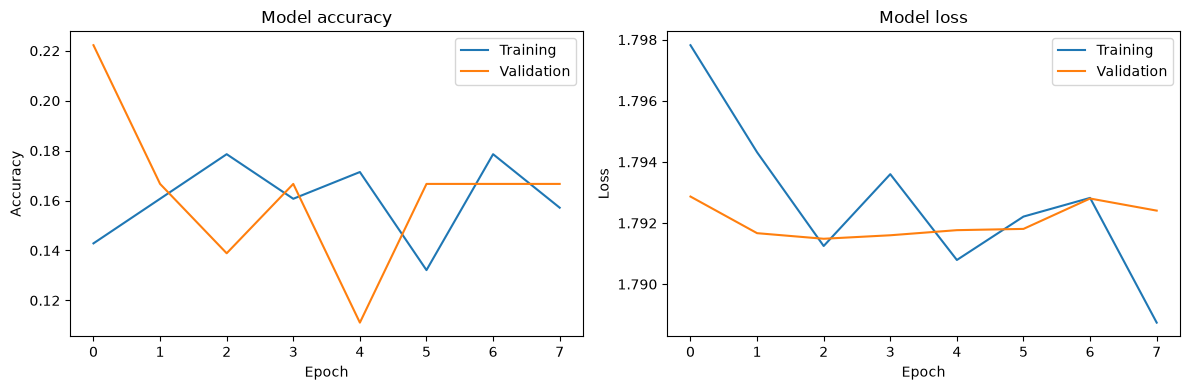

In [82]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [83]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test accuracy:", test_accuracy)
print("Test loss:", test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.1111 - loss: 1.7918
Test accuracy: 0.1111111119389534
Test loss: 1.7917938232421875


<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.